# Odyssey Transformer

## 1. Business Understanding

The goal of this project is to create a text predictor neural network using the transformer model. The model will be trained using Homer's Odyssey book downloaded from [Gutenberg](https://www.gutenberg.org). 

Using both Odyssey and Iliad was considered for more training data but was ultimately decided against due to differences in style. Odyssey was chosen for being prose instead of poem.

## 2. Data Understanding

Lets import the needed libraries and set keras backend to torch

In [12]:
import os
os.environ['KERAS_BACKEND'] = 'torch'

import numpy as np
import keras
import sentencepiece as spm
import matplotlib.pyplot as plt

print(f"Keras version: {keras.__version__}")
print(f"Keras backend: {keras.config.backend()}")

Keras version: 3.15.1
Keras backend: torch


Lets import and read the odyssey text file, which has around 540,000 characters, the pure textfile is 552kb which should be more than enough for this project. The file is manually cleaned up version of [The Odyssey by Homer](https://www.gutenberg.org/cache/epub/1727/pg1727.txt)

In [2]:
with open('./odyssey-clean.txt', 'r', encoding='utf-8-sig') as file:
    text = file.read()

print(f"Text length: {len(text)} characters")
print(f"First 100 characters:\n{text[:708]}")

Text length: 537244 characters
First 100 characters:
BOOK I


THE GODS IN COUNCIL—MINERVA’S VISIT TO ITHACA—THE CHALLENGE FROM
TELEMACHUS TO THE SUITORS.


Tell me, O Muse, of that ingenious hero who travelled far and wide
after he had sacked the famous town of Troy. Many cities did he visit,
and many were the nations with whose manners and customs he was
acquainted; moreover he suffered much by sea while trying to save his
own life and bring his men safely home; but do what he might he could
not save his men, for they perished through their own sheer folly in
eating the cattle of the Sun-god Hyperion; so the god prevented them
from ever reaching home. Tell me, too, about all these things, oh
daughter of Jove, from whatsoever source you may know them.


In [5]:
temp_file = 'odyssey-temp.txt'
with open(temp_file, 'w', encoding='utf-8') as f:
    f.write(text)

vocab_size = 19205
model_prefix = 'odyssey-sp'

"""
spm.SentencePieceTrainer.train(
    input=temp_file,
    model_prefix=model_prefix,
    vocab_size=vocab_size,
    character_coverage=1.0,  # Important for Finnish
    model_type='bpe',
    user_defined_symbols=['<PAD>', '<UNK>']
)
"""

sp = spm.SentencePieceProcessor()
sp.load(f"{model_prefix}.model")

test_text = "Tell me, O Muse"
tokens = sp.encode_as_pieces(test_text)
print(f"Tokenized example: {tokens}")
print(f"Vocabulary size: {sp.get_piece_size()}")

Tokenized example: ['▁Tell', '▁me', ',', '▁O', '▁Muse']
Vocabulary size: 19205


In [6]:
seq_length = 64
pieces = sp.encode_as_ids(text)
print(f"Total tokens: {len(pieces)}")

sequences = []
for i in range(0, len(pieces) - seq_length):
    sequences.append(pieces[i:i+seq_length+1])

sequences = np.array(sequences)
inputs = sequences[:, :-1] 
targets = sequences[:, 1:]

print(f"Number of sequences: {len(sequences)}")
print(f"Input shape: {inputs.shape}")
print(f"Target shape: {targets.shape}")

indices = np.arange(len(sequences))
np.random.shuffle(indices)

train_size = int(0.8 * len(sequences))
train_indices = indices[:train_size]
val_indices = indices[train_size:]

train_inputs, train_targets = inputs[train_indices], targets[train_indices]
val_inputs, val_targets = inputs[val_indices], targets[val_indices]


Total tokens: 118245
Number of sequences: 118181
Input shape: (118181, 64)
Target shape: (118181, 64)


In [10]:
def get_positional_encoding(max_len, d_model):
    positions = np.arange(max_len)[:, np.newaxis]
    angles = np.arange(d_model)[np.newaxis, :] / d_model
    angles = 1 / (10000**angles)

    pos_encoding = positions * angles
    pos_encoding[:, 0::2] = np.sin(pos_encoding[:, 0::2])
    pos_encoding[:, 1::2] = np.cos(pos_encoding[:, 1::2])

    return pos_encoding.astype("float32")

embed_dim = 256
num_heads = 4
ff_dim = 512
num_layers = 3

inputs = keras.Input(shape=(seq_length,))
embedding_layer = keras.layers.Embedding(sp.get_piece_size(), embed_dim)(inputs)

pos_encoding = get_positional_encoding(seq_length, embed_dim)
x = embedding_layer + pos_encoding

def create_causal_mask(size):
    return np.tril(np.ones((size, size), dtype="bool"))


for _ in range(num_layers):
    causal_mask = create_causal_mask(seq_length)

    attention_output = keras.layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=embed_dim // num_heads
    )(x, x, attention_mask=causal_mask)

    x = keras.layers.LayerNormalization(epsilon=1e-6)(x + attention_output)

    ffn = keras.Sequential([
        keras.layers.Dense(ff_dim, activation="relu"),
        keras.layers.Dense(embed_dim),
        keras.layers.Dropout(0.1)
    ])
    ffn_output = ffn(x)

    x = keras.layers.LayerNormalization(epsilon=1e-6)(x + ffn_output)

outputs = keras.layers.Dense(sp.get_piece_size())(x)
model = keras.Model(inputs=inputs, outputs=outputs)
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=3e-4),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

model.summary()


Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5       │ (None, 64)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_2         │ (None, 64, 256)   │  4,916,480 │ input_layer_5[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_8 (Add)         │ (None, 64, 256)   │          0 │ embedding_2[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 256)   │    263,168 │ add_8[0][0],      │
│ (MultiHeadAttentio… │                   │            │ add_8[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_9 (Add)         │ (None, 64, 256)   │          0 │ add_8[0][0],      │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 256)   │        512 │ add_9[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_3        │ (None, 64, 256)   │    262,912 │ layer_normalizat… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_10 (Add)        │ (None, 64, 256)   │          0 │ layer_normalizat… │
│                     │                   │            │ sequential_3[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 256)   │        512 │ add_10[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 256)   │    263,168 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_11 (Add)        │ (None, 64, 256)   │          0 │ layer_normalizat… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 256)   │        512 │ add_11[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_4        │ (None, 64, 256)   │    262,912 │ layer_normalizat… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_12 (Add)        │ (None, 64, 256)   │          0 │ layer_normalizat… │
│                     │                   │            │ sequential_4[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 256)   │        512 │ add_12[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 256)   │    263,168 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_13 (Add)        │ (None, 64, 256)   │          0 │ layer_normalizat… │
│                     │                   │            │ multi_head_atten

 Total params: 11,433,477 (43.62 MB)

 Trainable params: 11,433,477 (43.62 MB)

 Non-trainable params: 0 (0.00 B)

Comment out `model.fit` to prevent retraining

In [11]:
batch_size = 64
epochs = 10

"""
history = model.fit(
    train_inputs, train_targets,
    validation_data=(val_inputs, val_targets),
    batch_size=batch_size,
    epochs=epochs,
    callbacks=[
        keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=1),
        keras.callbacks.ModelCheckpoint('odyssey-best-model.keras', save_best_only=True)
    ]
)
"""

Epoch 1/10
1478/1478 ━━━━━━━━━━━━━━━━━━━━ 207s 137ms/step - accuracy: 0.1447 - loss: 5.2193 - val_accuracy: 0.2511 - val_loss: 3.8278 - learning_rate: 3.0000e-04
Epoch 2/10
1478/1478 ━━━━━━━━━━━━━━━━━━━━ 208s 141ms/step - accuracy: 0.4125 - loss: 2.7255 - val_accuracy: 0.6410 - val_loss: 1.5284 - learning_rate: 3.0000e-04
Epoch 3/10
1478/1478 ━━━━━━━━━━━━━━━━━━━━ 204s 138ms/step - accuracy: 0.7794 - loss: 0.9515 - val_accuracy: 0.9053 - val_loss: 0.4579 - learning_rate: 3.0000e-04
Epoch 4/10
1478/1478 ━━━━━━━━━━━━━━━━━━━━ 212s 143ms/step - accuracy: 0.9163 - loss: 0.3960 - val_accuracy: 0.9392 - val_loss: 0.2920 - learning_rate: 3.0000e-04
Epoch 5/10
1478/1478 ━━━━━━━━━━━━━━━━━━━━ 217s 147ms/step - accuracy: 0.9384 - loss: 0.2891 - val_accuracy: 0.9458 - val_loss: 0.2518 - learning_rate: 3.0000e-04
Epoch 6/10
1478/1478 ━━━━━━━━━━━━━━━━━━━━ 217s 147ms/step - accuracy: 0.9459 - loss: 0.2483 - val_accuracy: 0.9496 - val_loss: 0.2324 - learning_rate: 3.0000e-04
Epoch 7/10
1478/1478 ━━━━━━━

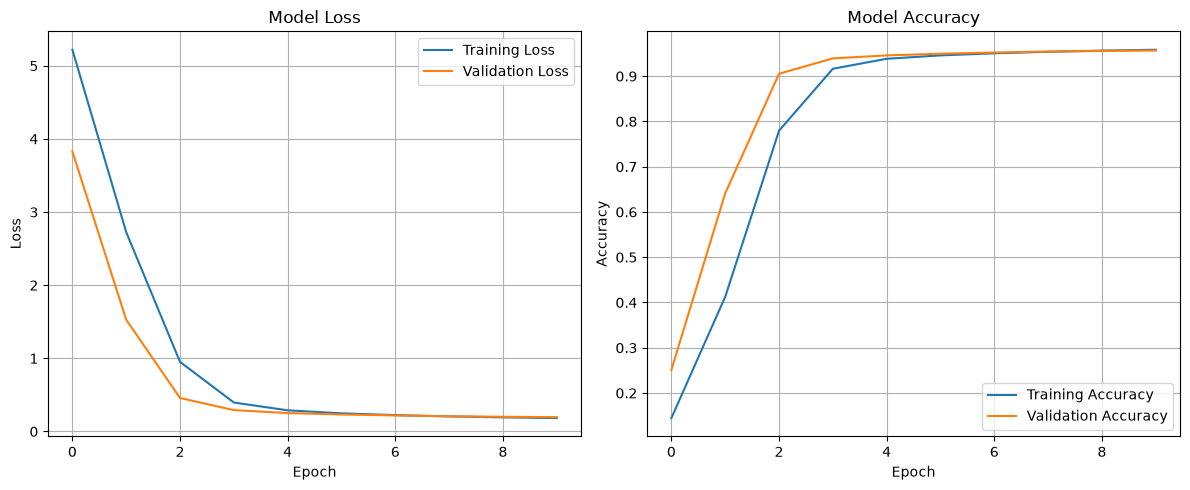

In [13]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid()
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.grid()
plt.legend()

plt.tight_layout()
plt.show()

In [16]:
##model.save('odyssey-model.keras')
##print("Model saved as 'odyssey-model.keras'")